# 02 Tren Topik dan Sentimen per Waktu

Bagaimana topik dan sentimen berubah dari waktu ke waktu. Contoh: komentar YouTube tentang MBG yang punya
tanggal. Label sentimen di sini hasil zero-shot, jadi trennya dibaca sebagai indikasi arah.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Melihat perubahan topik dan sentimen dari waktu ke waktu |
| **Unit prediksi** | Satu komentar mendapat topik dan polaritas, lalu dirata-rata per minggu |
| **Metrik** | NPMI paruh awal dan akhir, titik perubahan |
| **Masalah terbesar** | Topik bergeser seiring waktu: NPMI turun dari -0,0155 di paruh awal ke -0,1174 di paruh akhir pada k=6, jadi satu model topik tidak menjelaskan seluruh periode. |
| **Data contoh** | 5.000 komentar bertanggal, 17 Februari sampai 24 Juni 2026 |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** data punya kolom waktu, dan soal meminta analisis perubahan opini atau dampak suatu
peristiwa, misalnya sebelum dan sesudah kasus keracunan. Topik tanpa kolom waktu ada di folder `01`.

**Yang perlu diganti kalau datanya beda:**
- `load_data`, `TEXT_COL`, `TIME_COL`.
- `N_TOPICS` dan `DOMAIN_STOPWORDS`.
- `HYPOTHESES` kalau sentimennya berbeda.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: sentimen memakai kata kunci, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
TEXT_COL, TIME_COL = "comment", "published_at"
DOMAIN_STOPWORDS = {"mbg", "makan", "bergizi", "gratis", "program"}
HYPOTHESES = {
    "negatif": "Teks ini berisi kritik, keluhan, atau penolakan.",
    "netral": "Teks ini hanya menyampaikan informasi secara netral.",
    "positif": "Teks ini berisi dukungan, pujian, atau hal yang baik.",
}
NEGATIVE_WORDS = "korupsi gagal buruk bubarkan keracunan bohong rugi parah stop tolak".split()
POSITIVE_WORDS = "bagus mantap setuju dukung semoga terima kasih hebat baik sukses".split()
MIN_ROWS_PER_PERIOD = 30

SETTINGS = {
    "cepat": {"n_topics": 8, "topic_grid": [8], "sentiment_rows": 1500},
    "penuh": {"n_topics": 8, "topic_grid": [6, 8, 10, 12], "sentiment_rows": 5000},
}[MODE]

seed_everything(SEED)
install_offline("ruptures")
print(SETTINGS)

{'n_topics': 8, 'topic_grid': [6, 8, 10, 12], 'sentiment_rows': 5000}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Stopword.** Daftar ini hanya dipakai untuk merangkum kata kunci topik, bukan untuk input model
embedding. Tambahkan kata yang terlalu umum di kasus lu, misalnya `mbg` dan `makan`.

In [6]:
STOPWORDS = set(
    """
    ada adalah agar akan aku anda apa apakah atas atau bagaimana bagi bahkan bahwa banyak baru
    begitu belum benar berapa bersama bisa buat bukan cuma dalam dan dapat dari dengan di dia
    dong dulu gak ga gitu gue gua hanya harus hal ini itu iya jadi jangan juga jika kalau kalo
    kami kamu kan karena kata ke kita kok lagi lah lain lalu lebih lu lo masih mau maka mana
    memang mereka meski mungkin nah nanti ni nya oleh pada pak para pun punya saat saja sama
    sampai saya sebagai sebagainya sedang sudah sudah sih seperti siapa supaya tak tapi telah
    tentang terus tetapi tidak tuh udah untuk ya yaitu yang yg dgn dg krn utk tdk jg aja kalo
    aja nih deh kak bang bu ibu bapak sekarang semua setiap sangat tanpa ketika orang enggak
    quot amp mas mbak sih dah tau kayak kaya sampe gimana emang kenapa
    """.split()
)

## 4. EDA

Muat data, lalu cek rentang waktunya. Kalau rentangnya pendek atau komentar menumpuk di satu periode, tren
tidak bisa dibaca sembarangan.

In [7]:
def load_data() -> pd.DataFrame:
    frame = pd.read_csv(find_file("komentar-mbg.csv")).dropna(subset=[TEXT_COL, TIME_COL])
    frame[TIME_COL] = pd.to_datetime(frame[TIME_COL], errors="coerce", utc=True)
    frame = frame.dropna(subset=[TIME_COL]).drop_duplicates(TEXT_COL)
    return (
        frame.sample(n=min(N_ROWS, len(frame)), random_state=SEED)
        .sort_values(TIME_COL)
        .reset_index(drop=True)
    )


data = load_data()
span_days = (data[TIME_COL].max() - data[TIME_COL].min()).days
FREQ = "D" if span_days < 60 else ("W" if span_days < 400 else "MS")
data["periode"] = data[TIME_COL].dt.tz_localize(None).dt.to_period(FREQ[0]).dt.start_time
print(
    f"baris={len(data)} | {data[TIME_COL].min().date()} s.d. {data[TIME_COL].max().date()} | periode={FREQ}"
)
text_profile(data[TEXT_COL])

baris=5000 | 2026-02-17 s.d. 2026-06-24 | periode=W


baris                5000.0
kosong                  0.0
duplikat_persis_%       0.0
kata_median            12.0
kata_p95               48.0
kata_maks            1306.0
ada_url_%               0.0
ada_emoji_%            14.5
dtype: float64

Jumlah komentar per periode.

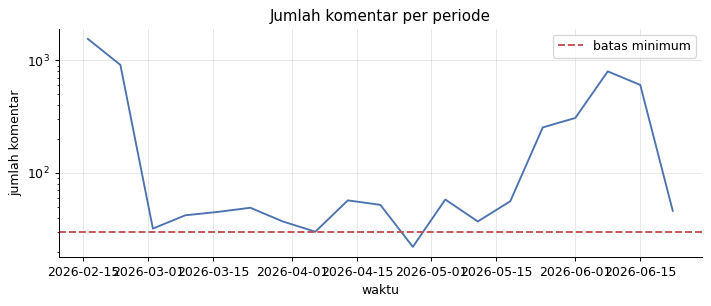

periode dengan cukup data: 18 dari 19


In [8]:
counts_time = data.groupby("periode").size()
fig, ax = plt.subplots()
ax.plot(counts_time.index, counts_time.values, color="#4C72B0")
ax.axhline(MIN_ROWS_PER_PERIOD, color="#C44E52", ls="--", label="batas minimum")
ax.set(title="Jumlah komentar per periode", xlabel="waktu", ylabel="jumlah komentar", yscale="log")
ax.legend()
plt.tight_layout()
plt.show()
print(
    "periode dengan cukup data:",
    int((counts_time >= MIN_ROWS_PER_PERIOD).sum()),
    "dari",
    len(counts_time),
)

**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| 18 dari 19 minggu punya cukup data | Agregasi mingguan layak dipakai |
| NPMI paruh akhir lebih rendah pada semua k yang dicoba | Pilih k dengan NPMI paruh akhir tertinggi, yaitu k=6, dan laporkan bahwa topik bergeser |
| Banyak komentar membahas tokoh, bukan programnya | Isi topik dibaca manual sebelum disimpulkan |

## 5. Preprocessing

Sama seperti folder `01`: HTML dibuang, slang dibakukan untuk kata kunci, dan stopword dibuang hanya pada
versi `words`.

In [9]:
import html  # noqa: E402

slang = load_slang_dict()
all_stopwords = STOPWORDS | DOMAIN_STOPWORDS
HTML_RE = re.compile(r"<[^>]+>")
data["clean"] = (
    data[TEXT_COL].astype(str).map(lambda t: clean_text(HTML_RE.sub(" ", html.unescape(t))))
)
data["words"] = data["clean"].map(
    lambda t: " ".join(
        w for w in re.findall(r"[a-z]{3,}", normalize_slang(t, slang)) if w not in all_stopwords
    )
)
data = data[data["words"].str.split().str.len() >= 3].reset_index(drop=True)
print("baris setelah dibersihkan:", len(data))

baris setelah dibersihkan: 4460


## 6. Validasi

Validasi temporal: model dilatih dari **paruh awal**, lalu kualitas topiknya dinilai pada **paruh akhir**.
Kalau NPMI jatuh jauh, topiknya berubah seiring waktu dan satu model topik tidak cukup.

In [10]:
from scipy.sparse import csr_matrix  # noqa: E402
from sklearn.decomposition import NMF  # noqa: E402
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer  # noqa: E402


def npmi_coherence(topics, doc_word) -> float:
    """Rata-rata NPMI pasangan kata kunci, dihitung dari kemunculan dalam dokumen."""
    n_docs = doc_word.shape[0]
    together = (doc_word.T @ doc_word).tocsr()
    doc_freq = np.asarray(doc_word.sum(0)).ravel()
    scores = []
    for words in topics:
        for a, word_a in enumerate(words):
            for word_b in words[a + 1 :]:
                joint = together[word_a, word_b] / n_docs
                if joint == 0:
                    scores.append(-1.0)
                    continue
                pmi = np.log(joint / (doc_freq[word_a] / n_docs * doc_freq[word_b] / n_docs))
                scores.append(pmi / -np.log(joint))
    return float(np.mean(scores))


_toy = csr_matrix(np.array([[1, 1, 0], [1, 1, 0], [0, 0, 1], [0, 0, 1]], dtype=np.int32))
assert abs(npmi_coherence([[0, 1]], _toy) - 1.0) < 1e-9

vectorizer = CountVectorizer(min_df=5, max_df=0.2, token_pattern=r"\b[a-z]{3,}\b")
counts = vectorizer.fit_transform(data["words"])
vocab = np.array(vectorizer.get_feature_names_out())
presence = (counts > 0).astype(np.int32)
tfidf = TfidfTransformer(sublinear_tf=True).fit_transform(counts)
half = len(data) // 2


def top_words(components) -> list[list[int]]:
    return [list(np.argsort(-row)[:10]) for row in components]


results: list[dict] = []
for k in SETTINGS["topic_grid"]:
    early = NMF(k, random_state=SEED, init="nndsvda", max_iter=400).fit(tfidf[:half])
    topics = top_words(early.components_)
    results.append(
        {
            "k": k,
            "npmi_paruh_awal": round(npmi_coherence(topics, presence[:half]), 4),
            "npmi_paruh_akhir": round(npmi_coherence(topics, presence[half:]), 4),
        }
    )
pd.DataFrame(results)

,k,npmi_paruh_awal,npmi_paruh_akhir
0,6,-0.0155,-0.1174
1,8,-0.0668,-0.2278
2,10,-0.0435,-0.1679
3,12,-0.0498,-0.1904


## 7. Baseline

Tren frekuensi kata. Sederhana, tapi sering sudah memperlihatkan peristiwa besar.

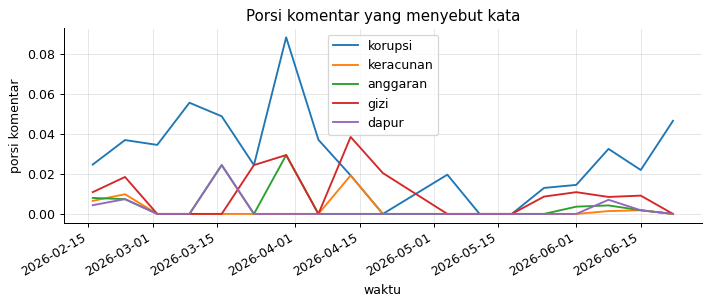

In [11]:
watch_words = [w for w in ["korupsi", "keracunan", "anggaran", "gizi", "dapur"] if w in vocab]
word_share = pd.DataFrame(
    {
        w: data["words"].str.contains(rf"\b{w}\b").groupby(data["periode"]).mean()
        for w in watch_words
    }
)
enough = counts_time[counts_time >= MIN_ROWS_PER_PERIOD].index
word_share = word_share.loc[word_share.index.isin(enough)]
fig, ax = plt.subplots()
word_share.plot(ax=ax)
ax.set(title="Porsi komentar yang menyebut kata", xlabel="waktu", ylabel="porsi komentar")
plt.tight_layout()
plt.show()

## 8. Model Utama

**Topik:** NMF dipilih karena di folder `01` kata kuncinya paling koheren, dan bisa jalan tanpa model dari
luar. **Sentimen:** zero-shot pada sampel, kalau pretrained boleh dipakai.

In [12]:
best_k = max(results, key=lambda r: r["npmi_paruh_akhir"])["k"]
nmf = NMF(best_k, random_state=SEED, init="nndsvda", max_iter=400)
doc_topic = nmf.fit_transform(tfidf)
data["topik"] = doc_topic.argmax(1)
topic_words = {t: ", ".join(vocab[w][:6]) for t, w in enumerate(top_words(nmf.components_))}
pd.Series(topic_words, name="kata_kunci")

0                    allah, semoga, selalu, tio, melindungi, swt
1                          bem, ugm, ketua, ijazah, palsu, bravo
2                     anak, muda, cerdas, bangsa, berani, pintar
3    rakyat, indonesia, mahasiswa, negara, pemerintah, mendukung
4               presiden, prabowo, bodoh, jokowi, pintar, negara
5                     tiyo, hati, semangat, sehat, kau, ardianto
Name: kata_kunci, dtype: object

Skor sentimen. Tanpa pretrained, sentimen dihitung dari selisih kata kunci positif dan negatif.

In [13]:
from transformers import AutoModelForSequenceClassification as NliModel  # noqa: E402
from transformers import AutoTokenizer as NliTokenizer  # noqa: E402


@torch.inference_mode()
def zero_shot(texts, hypotheses, batch_size=64) -> np.ndarray:
    tokenizer = NliTokenizer.from_pretrained(MODEL_DIR / "mdeberta_nli")
    model = NliModel.from_pretrained(MODEL_DIR / "mdeberta_nli").to(DEVICE).eval()
    entail = model.config.label2id.get("entailment", 0)
    scores = np.zeros((len(texts), len(hypotheses)))
    for h_index, hypothesis in enumerate(hypotheses):
        for start in range(0, len(texts), batch_size):
            batch = texts[start : start + batch_size]
            tokens = tokenizer(
                batch,
                [hypothesis] * len(batch),
                padding=True,
                truncation=True,
                max_length=128,
                return_tensors="pt",
            ).to(DEVICE)
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                scores[start : start + batch_size, h_index] = (
                    model(**tokens).logits.float()[:, entail].cpu().numpy()
                )
    del model
    torch.cuda.empty_cache()
    return torch.softmax(torch.tensor(scores), dim=1).numpy()


sample = data.sample(n=min(SETTINGS["sentiment_rows"], len(data)), random_state=SEED)
with stage("sentimen"):
    if USE_PRETRAINED:
        sentiment_probs = zero_shot(sample["clean"].tolist(), list(HYPOTHESES.values()))
        polarity = sentiment_probs[:, 2] - sentiment_probs[:, 0]
    else:
        negative_hits = sample["clean"].str.count("|".join(NEGATIVE_WORDS))
        positive_hits = sample["clean"].str.count("|".join(POSITIVE_WORDS))
        polarity = np.sign(positive_hits - negative_hits).to_numpy(dtype=float)
data.loc[sample.index, "polaritas"] = polarity
print(f"polaritas rata-rata: {np.mean(polarity):+.3f}")

[waktu] sentimen: 78 detik
polaritas rata-rata: -0.290


## 9. Post-processing

Periode dengan data terlalu sedikit dibuang, tren dihaluskan dengan rata-rata bergerak, lalu titik perubahan
dicari dengan `ruptures`. Titik perubahan adalah petunjuk untuk dicocokkan dengan peristiwa, bukan bukti
sebab akibat.

In [14]:
import ruptures  # noqa: E402

topic_share = pd.crosstab(data["periode"], data["topik"], normalize="index")
topic_share = topic_share.loc[topic_share.index.isin(enough)]
smooth_topics = topic_share.rolling(3, min_periods=1, center=True).mean()
polarity_trend = data.loc[data["periode"].isin(enough)].groupby("periode")["polaritas"].mean()
smooth_polarity = polarity_trend.rolling(3, min_periods=1, center=True).mean()

change_points = []
if len(smooth_polarity.dropna()) >= 8:
    signal = smooth_polarity.dropna().to_numpy()
    detector = ruptures.Pelt(model="rbf", min_size=3).fit(signal)
    change_points = [smooth_polarity.dropna().index[i] for i in detector.predict(pen=3)[:-1]]
print("titik perubahan polaritas:", [str(p.date()) for p in change_points] or "tidak ada")

titik perubahan polaritas: ['2026-03-23']


## 10. Post-analysis

**Porsi topik dari waktu ke waktu.**

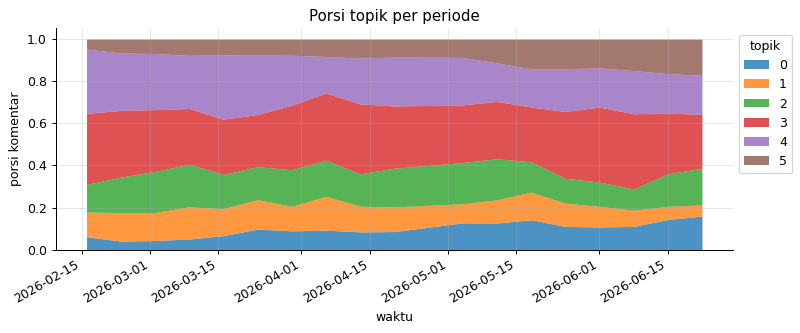

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.8))
smooth_topics.plot.area(ax=ax, stacked=True, alpha=0.8, linewidth=0)
ax.set(title="Porsi topik per periode", xlabel="waktu", ylabel="porsi komentar")
ax.legend(title="topik", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

**Tren polaritas** dengan titik perubahannya.

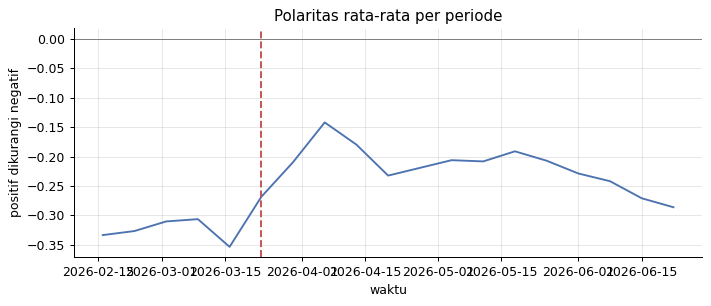

In [16]:
fig, ax = plt.subplots()
ax.plot(smooth_polarity.index, smooth_polarity.values, color="#4C72B0")
for point in change_points:
    ax.axvline(point, color="#C44E52", ls="--")
ax.axhline(0, color="gray", lw=0.8)
ax.set(title="Polaritas rata-rata per periode", xlabel="waktu", ylabel="positif dikurangi negatif")
plt.tight_layout()
plt.show()

**Ringkasan per topik:** ukuran, polaritas, dan arah perubahan porsi dari paruh awal ke paruh akhir.

In [17]:
middle = data["periode"].sort_values().iloc[len(data) // 2]
summary = pd.DataFrame(
    {
        "kata_kunci": topic_words,
        "jumlah": data["topik"].value_counts(),
        "polaritas": data.groupby("topik")["polaritas"].mean().round(3),
        "porsi_awal": data.loc[data["periode"] < middle, "topik"]
        .value_counts(normalize=True)
        .round(3),
        "porsi_akhir": data.loc[data["periode"] >= middle, "topik"]
        .value_counts(normalize=True)
        .round(3),
    }
).sort_values("jumlah", ascending=False)
summary.to_csv(RESULT_DIR / "ringkasan_topik.csv")
summary

,kata_kunci,jumlah,polaritas,porsi_awal,porsi_akhir
3,"rakyat, indonesia, mahasiswa, negara, pemerintah, mendukung",1468,-0.321,0.332,0.326
4,"presiden, prabowo, bodoh, jokowi, pintar, negara",1139,-0.505,0.309,0.202
2,"anak, muda, cerdas, bangsa, berani, pintar",571,-0.131,0.128,0.128
1,"bem, ugm, ketua, ijazah, palsu, bravo",478,-0.229,0.125,0.089
5,"tiyo, hati, semangat, sehat, kau, ardianto",422,-0.142,0.048,0.141
0,"allah, semoga, selalu, tio, melindungi, swt",382,-0.001,0.057,0.114


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [18]:
data[["periode", "topik", "polaritas"]].rename_axis("id").to_csv(RESULT_DIR / "submission.csv")
run_summary(
    "tren_topik_waktu",
    len(data),
    {
        "k": int(best_k),
        "validasi_temporal": results,
        "titik_perubahan": [str(p.date()) for p in change_points],
    },
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=tren_topik_waktu mode=penuh n_rows=4460 total_detik=98 gpu=True
{
 "k": 6,
 "validasi_temporal": [
  {
   "k": 6,
   "npmi_paruh_awal": -0.0155,
   "npmi_paruh_akhir": -0.1174
  },
  {
   "k": 8,
   "npmi_paruh_awal": -0.0668,
   "npmi_paruh_akhir": -0.2278
  },
  {
   "k": 10,
   "npmi_paruh_awal": -0.0435,
   "npmi_paruh_akhir": -0.1679
  },
  {
   "k": 12,
   "npmi_paruh_awal": -0.0498,
   "npmi_paruh_akhir": -0.1904
  }
 ],
 "titik_perubahan": [
  "2026-03-23"
 ]
}


**Poin untuk presentasi**

- Ditemukan satu titik perubahan polaritas di sekitar 23 Maret 2026.
- Polaritas rata-rata -0,290. Topik presiden paling negatif (-0,505), dan porsinya turun dari 30,9% ke 20,2%.
- NPMI negatif menandakan koherensi kata kunci lemah, jadi kesimpulan topik di notebook ini perlu didukung contoh komentar.
- Polaritas berasal dari model, bukan label manusia. Sebutkan ini saat presentasi.